# Day 12 — Inventory Constraints and Pricing Recommendations

This notebook applies inventory-level constraints to the Day 11 pricing scenarios
and produces a ranked recommendation table. It loads the validated DML coefficient
and simulator results from Day 10 and Day 11.

---

> **Inventory constraint caveat:** The Inventory Level column is recorded at the same
> time as Price and Units Sold. Its definition and timing are ambiguous — it may represent
> beginning-of-period stock, end-of-period stock, or something else. We apply the inventory
> cap as a **provisional constraint only** and explicitly flag this limitation.

> **Recommendation scope:** This notebook produces a **research prototype** for discussion.
> It does NOT produce an automatic pricing decision. The DML estimate is not statistically
> significant and causal assumptions have not been fully validated.

In [1]:
# Cell 1: Imports
import warnings
warnings.filterwarnings('ignore')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

PROJECT_ROOT = Path.home() / 'Documents' / 'EconoCausal'
print('Imports complete. Project root:', PROJECT_ROOT)

Imports complete. Project root: /Users/hasikaippili/Documents/EconoCausal


## 1 · Load Validated Day 10 DML Results and Day 11 Simulator Output

In [2]:
# Cell 2: Load Day 10 and Day 11 results
DML_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dml_validated_results.json'
SIM_PATH = PROJECT_ROOT / 'data' / 'processed' / 'pricing_simulator_results.json'

for p in [DML_PATH, SIM_PATH]:
    if not p.exists():
        raise FileNotFoundError(
            f'Required file not found: {p}\n'
            'Run notebooks 08 (Day 10) and 09 (Day 11) first.'
        )

with open(DML_PATH, 'r') as f:
    dml_results = json.load(f)

with open(SIM_PATH, 'r') as f:
    sim_data = json.load(f)

# DML coefficient from Spec 1
spec     = dml_results['spec1']
THETA    = spec['theta']
CI_LOW   = spec['ci_low']
CI_HIGH  = spec['ci_high']
P_VALUE  = spec['p_value']
T_RES_SD = spec['t_res_std']

# Simulator baseline
PRODUCT_ID  = sim_data['product_id']
STORE_ID    = sim_data['store_id']
BASE_PRICE  = sim_data['baseline_price']
BASE_UNITS  = sim_data['baseline_units']
BASE_REV    = sim_data['baseline_revenue']
BASE_INV    = sim_data['baseline_inventory']
PRICE_OBS_MIN = sim_data['price_obs_min']
PRICE_OBS_MAX = sim_data['price_obs_max']

scenarios_df = pd.DataFrame(sim_data['scenarios'])

print('Day 10/11 data loaded:')
print(f'  Product: {PRODUCT_ID} | Store: {STORE_ID}')
print(f'  DML theta     : {THETA:+.6f}')
print(f'  95% CI        : [{CI_LOW:.6f}, {CI_HIGH:.6f}]')
print(f'  p-value       : {P_VALUE:.4f}')
print(f'  Base price    : ${BASE_PRICE:.2f}')
print(f'  Base units    : {BASE_UNITS:.0f}')
print(f'  Base revenue  : ${BASE_REV:.2f}')
print(f'  Base inventory: {BASE_INV:.0f} (timing uncertain - provisional constraint)')
print(f'  Scenarios loaded: {len(scenarios_df)}')

Day 10/11 data loaded:
  Product: P0001 | Store: S001
  DML theta     : +0.010699
  95% CI        : [-0.019671, 0.041069]
  p-value       : 0.4899
  Base price    : $55.13
  Base units    : 173
  Base revenue  : $9537.49
  Base inventory: 195 (timing uncertain - provisional constraint)
  Scenarios loaded: 5


## 2 · Warnings and Reliability Checks

Before producing recommendations, we check for known reliability issues.

In [3]:
# Cell 3: Reliability checks and warnings
warnings_list = []

if not dml_results.get('validated', False):
    warnings_list.append('DML results are NOT validated. Re-run Day 10 notebook.')

if P_VALUE > 0.10:
    warnings_list.append(
        f'DML price coefficient is NOT statistically significant (p={P_VALUE:.4f}). '
        'Revenue rankings are highly uncertain.'
    )

if T_RES_SD < 1.0:
    warnings_list.append(
        f'Residual price variation is very small (SD={T_RES_SD:.4f}). '
        'Coefficient may be unreliable.'
    )

theta2 = dml_results['spec2']['theta']
coeff_shift_pct = abs(THETA - theta2) / abs(THETA) * 100 if THETA != 0 else float('inf')
if coeff_shift_pct > 25:
    warnings_list.append(
        f'Coefficient shifts {coeff_shift_pct:.1f}% when Inventory Level is added as control. '
        'Results are sensitive to control selection.'
    )

# Inventory timing warning - always raised since timing is unknown
warnings_list.append(
    'INVENTORY TIMING: Inventory Level timing is unknown. The inventory cap is '
    'PROVISIONAL and may not represent available stock at time of sale.'
)

# Unit cost warning
warnings_list.append('Unit cost data is unavailable. Revenue ranking != profit ranking.')

if scenarios_df['Extrapolates'].any():
    n_extrap = scenarios_df['Extrapolates'].sum()
    warnings_list.append(
        f'{n_extrap} scenario(s) extrapolate beyond observed price range '
        f'[${PRICE_OBS_MIN:.2f}, ${PRICE_OBS_MAX:.2f}]. Predictions are less reliable.'
    )

print('ACTIVE WARNINGS:')
for i, w in enumerate(warnings_list, 1):
    print(f'  {i}. {w}')

if len(warnings_list) > 0:
    print(f'\nTotal: {len(warnings_list)} warning(s). Recommendations are RESEARCH PROTOTYPE only.')

ACTIVE WARNINGS:
  1. DML price coefficient is NOT statistically significant (p=0.4899). Revenue rankings are highly uncertain.
  2. Coefficient shifts 282.0% when Inventory Level is added as control. Results are sensitive to control selection.
  3. INVENTORY TIMING: Inventory Level timing is unknown. The inventory cap is PROVISIONAL and may not represent available stock at time of sale.
  4. Unit cost data is unavailable. Revenue ranking != profit ranking.

Total: 4 warning(s). Recommendations are RESEARCH PROTOTYPE only.


## 3 · Inventory Constraint Application

We cap estimated units at Inventory Level as a provisional constraint.
Since the timing of Inventory Level is uncertain, this is explicitly labelled
**provisional** and should not be treated as a hard operational limit.

In [4]:
# Cell 4: Apply inventory constraint
# We apply the cap provisionally, since timing is unclear
INV_CAP = BASE_INV  # provisional: use baseline inventory as max sellable units

rec = scenarios_df.copy()

rec['Inv Cap (provisional)'] = INV_CAP
rec['Units (inv-capped)'] = rec['Est Units Sold'].clip(upper=INV_CAP)
rec['Units constrained?'] = rec['Est Units Sold'] > INV_CAP

# Revenue with inventory cap applied
rec['Rev (inv-capped) ($)'] = (rec['Price ($)'] * rec['Units (inv-capped)']).round(2)
rec['Rev Change (capped) ($)'] = (rec['Rev (inv-capped) ($)'] - BASE_REV).round(2)
rec['Rev Change (capped) (%)'] = (
    rec['Rev Change (capped) ($)'] / BASE_REV * 100
).round(2)

print(f'Inventory cap applied: {INV_CAP:.0f} units (PROVISIONAL - timing uncertain)')
print(f'Scenarios where estimated demand exceeds cap: {rec["Units constrained?"].sum()}')
print()

display_cols = [
    'Scenario', 'Price ($)', 'Est Units Sold', 'Units (inv-capped)',
    'Units constrained?', 'Rev (inv-capped) ($)', 'Rev Change (capped) ($)', 'Extrapolates'
]
print('Inventory-Constrained Scenario Table (PROVISIONAL):')
display(rec[display_cols].set_index('Scenario'))

Inventory cap applied: 195 units (PROVISIONAL - timing uncertain)
Scenarios where estimated demand exceeds cap: 0

Inventory-Constrained Scenario Table (PROVISIONAL):


,Price ($),Est Units Sold,Units (inv-capped),Units constrained?,Rev (inv-capped) ($),Rev Change (capped) ($),Extrapolates
Scenario,,,,,,,
-10%,49.62,172.94,172.94,False,8581.28,-956.21,False
-5%,52.37,172.97,172.97,False,9058.44,-479.05,False
+0%,55.13,173.00,173.00,False,9537.49,0.00,False
+5%,57.89,173.03,173.03,False,10016.71,479.22,False
+10%,60.64,173.06,173.06,False,10494.36,956.87,False


## 4 · Scenario Ranking

We rank scenarios by **inventory-constrained estimated revenue** (descending).
This is a transparent, reproducible rule. It does not maximise profit.

In [5]:
# Cell 5: Rank and recommend
rec['Rank (by capped revenue)'] = rec['Rev (inv-capped) ($)'].rank(
    ascending=False, method='min'
).astype(int)

rec_sorted = rec.sort_values('Rank (by capped revenue)')

print('RANKED SCENARIOS (by inventory-constrained estimated revenue):')
print('=' * 85)
print('Ranking rule: descending estimated revenue after provisional inventory cap.')
print('This is NOT profit maximisation (unit costs unavailable).')
print('=' * 85)

for _, row in rec_sorted.iterrows():
    extrap = ' [EXTRAPOLATES]' if row['Extrapolates'] else ''
    capped = ' [INV CAP APPLIED]' if row['Units constrained?'] else ''
    print(
        f"  Rank {int(row['Rank (by capped revenue)']):>2} | {row['Scenario']:>5} | "
        f"Price=${row['Price ($)']:>6.2f} | "
        f"Est units={row['Units (inv-capped)']:>6.1f} | "
        f"Est rev=${row['Rev (inv-capped) ($)']:>8.2f} | "
        f"Rev chg={row['Rev Change (capped) (%)']:>+6.2f}%"
        f"{extrap}{capped}"
    )

best = rec_sorted.iloc[0]
print()
print(f'Top-ranked scenario: {best["Scenario"]} at ${best["Price ($)"]:.2f}')
print(f'  Est units (inv-capped): {best["Units (inv-capped)"]:.1f}')
print(f'  Est revenue            : ${best["Rev (inv-capped) ($)"]:.2f}')
print(f'  Rev change vs baseline : {best["Rev Change (capped) (%)"]:.2f}%')

RANKED SCENARIOS (by inventory-constrained estimated revenue):
Ranking rule: descending estimated revenue after provisional inventory cap.
This is NOT profit maximisation (unit costs unavailable).
  Rank  1 |  +10% | Price=$ 60.64 | Est units= 173.1 | Est rev=$10494.36 | Rev chg=+10.03%
  Rank  2 |   +5% | Price=$ 57.89 | Est units= 173.0 | Est rev=$10016.71 | Rev chg= +5.02%
  Rank  3 |   +0% | Price=$ 55.13 | Est units= 173.0 | Est rev=$ 9537.49 | Rev chg= +0.00%
  Rank  4 |   -5% | Price=$ 52.37 | Est units= 173.0 | Est rev=$ 9058.44 | Rev chg= -5.02%
  Rank  5 |  -10% | Price=$ 49.62 | Est units= 172.9 | Est rev=$ 8581.28 | Rev chg=-10.03%

Top-ranked scenario: +10% at $60.64
  Est units (inv-capped): 173.1
  Est revenue            : $10494.36
  Rev change vs baseline : 10.03%


## 5 · Baseline Comparison

In [6]:
# Cell 6: Baseline comparison
baseline_row = rec.loc[rec['Scenario'] == '+0%'].iloc[0]
best_row = rec_sorted.iloc[0]

print('BASELINE vs TOP-RANKED SCENARIO:')
print('-' * 55)
print(f'{"Metric":<30} {"Baseline (0%)":>12} {"Top-ranked":>12}')
print('-' * 55)
print(f'{"Scenario":<30} {"0% (baseline)":>12} {best_row["Scenario"]:>12}')
print(f'{"Price ($)":<30} ${BASE_PRICE:>11.2f} ${best_row["Price ($)"]:>11.2f}')
print(f'{"Est Units Sold":<30} {BASE_UNITS:>12.1f} {best_row["Units (inv-capped)"]:>12.1f}')
print(f'{"Est Revenue ($)":<30} ${BASE_REV:>11.2f} ${best_row["Rev (inv-capped) ($)"]:>11.2f}')
print(f'{"Rev Change ($)":<30} {0:>12.2f} {best_row["Rev Change (capped) ($)"]:>12.2f}')
print(f'{"Rev Change (%)":<30} {0:>12.2f}% {best_row["Rev Change (capped) (%)"]:.2f}%')
print('-' * 55)
print()
print('NOTE: Revenue change is relative to the baseline observation.')
print('The top-ranked scenario is based on a linear approximation with significant uncertainty.')

BASELINE vs TOP-RANKED SCENARIO:
-------------------------------------------------------
Metric                         Baseline (0%)   Top-ranked
-------------------------------------------------------
Scenario                       0% (baseline)         +10%
Price ($)                      $      55.13 $      60.64
Est Units Sold                        173.0        173.1
Est Revenue ($)                $    9537.49 $   10494.36
Rev Change ($)                         0.00       956.87
Rev Change (%)                         0.00% 10.03%
-------------------------------------------------------

NOTE: Revenue change is relative to the baseline observation.
The top-ranked scenario is based on a linear approximation with significant uncertainty.


## 6 · Visualisation

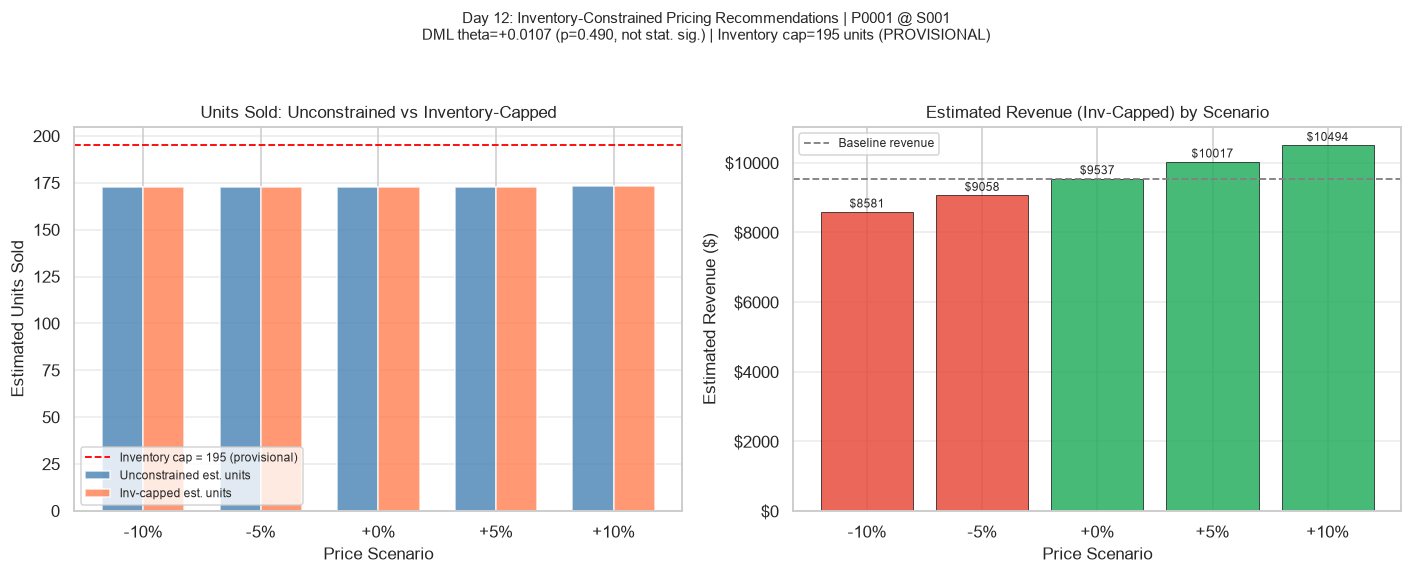

In [7]:
# Cell 7: Visualisation
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel A: Unconstrained vs inventory-capped units
ax = axes[0]
x = np.arange(len(rec))
w = 0.35
ax.bar(x - w/2, rec['Est Units Sold'], width=w, color='steelblue', alpha=0.8,
       label='Unconstrained est. units')
ax.bar(x + w/2, rec['Units (inv-capped)'], width=w, color='coral', alpha=0.8,
       label='Inv-capped est. units')
ax.axhline(INV_CAP, color='red', linestyle='--', linewidth=1.2,
           label=f'Inventory cap = {INV_CAP:.0f} (provisional)')
ax.set_xticks(x)
ax.set_xticklabels(rec['Scenario'].values)
ax.set_xlabel('Price Scenario', fontsize=11)
ax.set_ylabel('Estimated Units Sold', fontsize=11)
ax.set_title('Units Sold: Unconstrained vs Inventory-Capped', fontsize=11)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.4)

# Panel B: Revenue by scenario (capped)
ax = axes[1]
bar_cols = ['#27ae60' if r >= BASE_REV else '#e74c3c' for r in rec['Rev (inv-capped) ($)']]
bars = ax.bar(rec['Scenario'], rec['Rev (inv-capped) ($)'],
              color=bar_cols, edgecolor='black', linewidth=0.5, alpha=0.85)
ax.axhline(BASE_REV, color='grey', linestyle='--', linewidth=1.2, label='Baseline revenue')

for bar, val in zip(bars, rec['Rev (inv-capped) ($)']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(rec['Rev (inv-capped) ($)']) * 0.005,
        f'${val:.0f}',
        ha='center', va='bottom', fontsize=8
    )

ax.set_xlabel('Price Scenario', fontsize=11)
ax.set_ylabel('Estimated Revenue ($)', fontsize=11)
ax.set_title('Estimated Revenue (Inv-Capped) by Scenario', fontsize=11)
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.4)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.0f'))

plt.suptitle(
    f'Day 12: Inventory-Constrained Pricing Recommendations | {PRODUCT_ID} @ {STORE_ID}\n'
    f'DML theta={THETA:+.4f} (p={P_VALUE:.3f}, not stat. sig.) | '
    f'Inventory cap={INV_CAP:.0f} units (PROVISIONAL)',
    fontsize=10, y=1.04
)
plt.tight_layout()
plt.show()

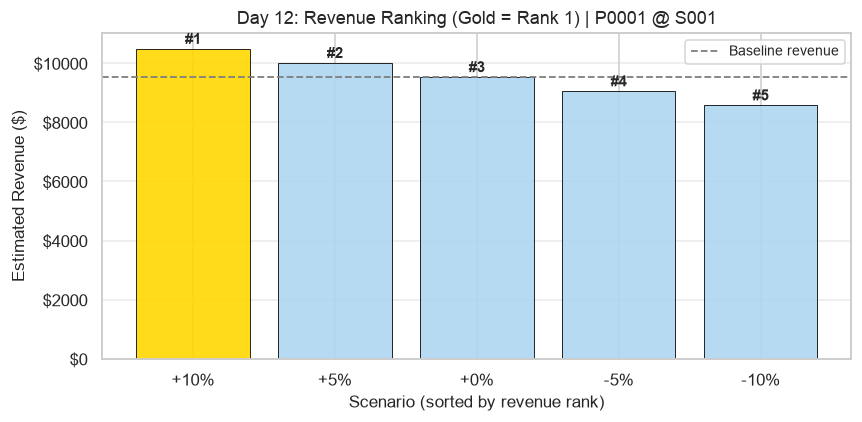

Gold bar = Rank 1 (highest estimated inventory-capped revenue).


In [8]:
# Cell 8: Revenue ranking bar chart with rank labels
fig, ax = plt.subplots(figsize=(8, 4))

sorted_scen = rec_sorted['Scenario'].values
sorted_rev  = rec_sorted['Rev (inv-capped) ($)'].values
ranks = rec_sorted['Rank (by capped revenue)'].values
bar_cols2 = ['gold' if r == 1 else '#aed6f1' for r in ranks]

bars = ax.bar(sorted_scen, sorted_rev, color=bar_cols2,
              edgecolor='black', linewidth=0.6, alpha=0.9)

for bar, rank, val in zip(bars, ranks, sorted_rev):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(sorted_rev) * 0.005,
        f'#{rank}',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.axhline(BASE_REV, color='grey', linestyle='--', linewidth=1.2, label='Baseline revenue')
ax.set_xlabel('Scenario (sorted by revenue rank)', fontsize=11)
ax.set_ylabel('Estimated Revenue ($)', fontsize=11)
ax.set_title(
    f'Day 12: Revenue Ranking (Gold = Rank 1) | {PRODUCT_ID} @ {STORE_ID}',
    fontsize=12
)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.4)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('$%.0f'))
plt.tight_layout()
plt.show()

print('Gold bar = Rank 1 (highest estimated inventory-capped revenue).')

## 7 · Why Revenue Ranking is NOT Profit Maximisation

Profit = Revenue − Total Cost  
Total Cost = Unit Cost × Units Sold + Fixed Costs

Without unit cost data, we cannot compute profit. A scenario with higher revenue
but proportionally higher cost could produce **lower profit**. For example,
if variable cost is $40 per unit:
- A low-price scenario selling more units incurs higher variable cost
- Net effect on profit depends on the margin at each price point

**This is a revenue-maximisation heuristic only**, not a profit-optimal recommendation.

## 8 · Assumptions and Limitations Summary

In [9]:
# Cell 9: Final summary
print('=' * 75)
print('DAY 12 - PRICING RECOMMENDATIONS SUMMARY')
print('=' * 75)
print(f'Product: {PRODUCT_ID} | Store: {STORE_ID}')
print(f'DML theta (Spec 1) : {THETA:+.6f} units per $1 price increase')
print(f'  95% CI           : [{CI_LOW:.6f}, {CI_HIGH:.6f}]')
print(f'  p-value          : {P_VALUE:.4f}  (NOT statistically significant)')
print(f'Inventory cap      : {INV_CAP:.0f} units (PROVISIONAL - timing unknown)')
print()
print('Ranked Recommendations (by inv-capped estimated revenue):')
for _, row in rec_sorted.iterrows():
    print(
        f"  #{int(row['Rank (by capped revenue)']):>2} | Scenario {row['Scenario']:>5} | "
        f"Price ${row['Price ($)']:>6.2f} | "
        f"Units {row['Units (inv-capped)']:>6.1f} | "
        f"Revenue ${row['Rev (inv-capped) ($)']:>8.2f} | "
        f"Rev chg {row['Rev Change (capped) (%)']:>+6.2f}%"
    )
print()
print('ASSUMPTIONS AND LIMITATIONS:')
print('  1. Linear demand approximation near baseline — not valid far from it.')
print('  2. DML coefficient is NOT statistically significant (p > 0.10).')
print('  3. Spec 2 sensitivity: coefficient changes materially with control set.')
print('  4. Inventory Level timing is ambiguous: provisional constraint only.')
print('  5. Unit cost unknown: revenue != profit. Profit maximisation impossible.')
print('  6. No data on promotions, competitor prices, holidays, or demand shocks.')
print('  7. Results apply to one product-store combination — do not generalise.')
print('  8. This is a RESEARCH PROTOTYPE — not a production pricing system.')
print('=' * 75)

DAY 12 - PRICING RECOMMENDATIONS SUMMARY
Product: P0001 | Store: S001
DML theta (Spec 1) : +0.010699 units per $1 price increase
  95% CI           : [-0.019671, 0.041069]
  p-value          : 0.4899  (NOT statistically significant)
Inventory cap      : 195 units (PROVISIONAL - timing unknown)

Ranked Recommendations (by inv-capped estimated revenue):
  # 1 | Scenario  +10% | Price $ 60.64 | Units  173.1 | Revenue $10494.36 | Rev chg +10.03%
  # 2 | Scenario   +5% | Price $ 57.89 | Units  173.0 | Revenue $10016.71 | Rev chg  +5.02%
  # 3 | Scenario   +0% | Price $ 55.13 | Units  173.0 | Revenue $ 9537.49 | Rev chg  +0.00%
  # 4 | Scenario   -5% | Price $ 52.37 | Units  173.0 | Revenue $ 9058.44 | Rev chg  -5.02%
  # 5 | Scenario  -10% | Price $ 49.62 | Units  172.9 | Revenue $ 8581.28 | Rev chg -10.03%

ASSUMPTIONS AND LIMITATIONS:
  1. Linear demand approximation near baseline — not valid far from it.
  2. DML coefficient is NOT statistically significant (p > 0.10).
  3. Spec 2 sensit